In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
import numpy as np
from pathlib import Path
import random

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
VALIDATION_SHARE = 0.20
DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

In [4]:
# Загружаем Fashion-MNIST и показываем несколько исходных изображений с названиями классов.
from torchvision import datasets

train_raw = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)

In [ ]:
# Создаём collate_fn: он объединяет raw-изображения, переносит батч на device и нормализует пиксели.
from typing import TypeAlias, Union

NORMALIZE_MEAN = 0.2860
NORMALIZE_STD = 0.3530

# Один элемент батча: изображение и соответствующая ему метка.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]

# Устройство можно задать строкой, объектом torch.device или индексом GPU.
DeviceLikeType: TypeAlias = Union[str, torch.device, int]


class FashionMNISTCollator:
    """Подготавливает батч изображений Fashion-MNIST для CNN."""

    def __init__(self, device: DeviceLikeType) -> None:
        # Сохраняем целевое устройство, на котором будут выполняться преобразования.
        self.device = torch.device(device)

        self.mean = torch.tensor(
            NORMALIZE_MEAN,
            dtype=torch.float32,
            device=device,
        ).view(1, 1, 1, 1)
        self.std = torch.tensor(
            NORMALIZE_STD,
            dtype=torch.float32,
            device=device,
        ).view(1, 1, 1, 1)

    def __call__(self, batch: list[TensorPair]) -> TensorPair:
        # Разделяем список элементов батча на изображения и соответствующие метки.
        images, targets = zip(*batch)

        # Объединяем изображения в тензор [B, H, W] и добавляем размерность канала.
        # Одновременно получаем форму [B, 1, H, W].
        images = torch.stack(images).unsqueeze(1)

        # Переносим изображения на выбранное устройство и преобразуем в float32.
        # Деление на 255 переводит значения пикселей из [0, 255] в [0, 1].
        images = images.to(device=self.device, dtype=torch.float32) / 255.0

        # Объединяем метки в один тензор и переносим их на то же устройство.
        targets = torch.stack(targets).to(self.device)

        # Нормализуем по статистикам Fashion-MNIST; broadcast применяется ко всему батчу.
        images = (images - self.mean) / self.std

        # Возвращаем готовый батч признаков и меток.
        return images, targets

In [ ]:
# Разделяем обучающую часть Fashion MNIST на train и validation, сохраняя test отдельно.
from torch.utils.data import DataLoader, TensorDataset, Subset

train_full_dataset = TensorDataset(train_raw.data, train_raw.targets.long())
test_dataset = TensorDataset(test_raw.data, test_raw.targets.long())

split_generator = torch.Generator().manual_seed(SEED)
permuted_indices = torch.randperm(
    len(train_full_dataset), generator=split_generator
).tolist()

validation_size = int(len(permuted_indices) * VALIDATION_SHARE)
validation_indices = permuted_indices[:validation_size]
train_indices = permuted_indices[validation_size:]

train_dataset = Subset(train_full_dataset, train_indices)
validation_dataset = Subset(train_full_dataset, validation_indices)

In [ ]:
# Создаём все DataLoader с одним collator.
collator = FashionMNISTCollator(device=device)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collator,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)

In [ ]:
# Определяем CNN; значения параметров по умолчанию в точности задают базовую архитектуру из задания.
import torch.nn as nn


class FashionCNN(nn.Module):
    """Свёрточный классификатор Fashion-MNIST с настраиваемой регуляризацией."""

    def __init__(
        self,
        num_classes: int = 10,
        channels: tuple[int, int] = (32, 64),
        kernel_size: int = 3,
        stride: int = 1,
        use_batch_norm: bool = False,
        dropout_type: str = "none",
        dropout_p: float = 0.25,
    ) -> None:
        super().__init__()

        if kernel_size % 2 == 0:
            raise ValueError("Для этой реализации используйте нечётный kernel_size.")
        if dropout_type not in {"none", "dropout", "dropout2d"}:
            raise ValueError("dropout_type должен быть none, dropout или dropout2d.")

        padding = kernel_size // 2
        channels_1, channels_2 = channels

        # В базовом режиме этот блок совпадает с Conv2d -> ReLU -> MaxPool2d.
        block1_layers: list[nn.Module] = [
            nn.Conv2d(
                1,
                channels_1,
                kernel_size,
                stride=stride,
                padding=padding,
            )
        ]
        if use_batch_norm:
            block1_layers.append(nn.BatchNorm2d(channels_1))
        block1_layers.extend([nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2)])
        self.block1 = nn.Sequential(*block1_layers)

        # Второй блок получает карты признаков первого блока и увеличивает число каналов.
        block2_layers: list[nn.Module] = [
            nn.Conv2d(
                channels_1,
                channels_2,
                kernel_size,
                stride=stride,
                padding=padding,
            )
        ]
        if use_batch_norm:
            block2_layers.append(nn.BatchNorm2d(channels_2))
        block2_layers.extend([nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2)])
        self.block2 = nn.Sequential(*block2_layers)

        # Вычисляем пространственный размер после двух свёрток и двух pooling.
        spatial_size = 28
        for _ in range(2):
            spatial_size = (spatial_size + 2 * padding - kernel_size) // stride + 1
            spatial_size = (spatial_size - 2) // 2 + 1
        if spatial_size < 1:
            raise ValueError("Параметры свёрток слишком сильно уменьшают изображение.")

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels_2 * spatial_size * spatial_size, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

        # Dropout применяется к картам признаков после каждого свёрточного блока.
        if dropout_type == "dropout":
            self.dropout1 = nn.Dropout(p=dropout_p)
            self.dropout2 = nn.Dropout(p=dropout_p)
        elif dropout_type == "dropout2d":
            self.dropout1 = nn.Dropout2d(p=dropout_p)
            self.dropout2 = nn.Dropout2d(p=dropout_p)
        else:
            self.dropout1 = nn.Identity()
            self.dropout2 = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты формы [batch_size, num_classes]."""
        x = self.dropout1(self.block1(x))
        x = self.dropout2(self.block2(x))
        return self.classifier(x)

In [9]:
def count_parameters(model: nn.Module) -> int:
    """Возвращает число обучаемых параметров модели."""
    return sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )

In [10]:
# Сравниваем количество параметров и лучшие значения validation-метрик MLP и CNN.
import pandas as pd


def summarize_history(history_df: pd.DataFrame) -> dict[str, float | int]:
    """Возвращает эпоху минимального val_loss и максимальную validation accuracy."""
    per_epoch = history_df.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()
    best_loss_epoch = int(per_epoch["val_loss"].idxmin())
    return {
        "best_loss_epoch": best_loss_epoch + 1,
        "best_val_loss": float(per_epoch.loc[best_loss_epoch, "val_loss"]),
        "best_val_accuracy": float(per_epoch["val_accuracy"].max()),
    }

In [11]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
# Создаём функцию для запуска одного варианта CNN и возврата логов и истории по эпохам.
from templates.lit import LitModel


def fit_cnn_variant(
    experiment_name: str,
    *,
    channels: tuple[int, int] = (32, 64),
    kernel_size: int = 3,
    stride: int = 1,
    use_batch_norm: bool = True,
    dropout_type: str = "none",
    dropout_p: float = 0.25,
    experiments: list | None = None,
):
    """Обучает один вариант FashionCNN на фиксированных train/validation данных."""
    variant = LitModel(
        model=FashionCNN,
        num_classes=10,
        channels=channels,
        kernel_size=kernel_size,
        stride=stride,
        use_batch_norm=use_batch_norm,
        dropout_type=dropout_type,
        dropout_p=dropout_p,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=SEED,
    )

    variant_metrics = variant.fit(
        train_loader=train_loader,
        validation_loader=validation_loader,
        epochs=MAX_EPOCHS,
        patience=MAX_EPOCHS,
    )

    model = variant.to(device).model.eval()

    variant_history = variant_metrics.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()

    params = count_parameters(model)
    summary = summarize_history(variant_metrics)

    print(f"Эксперимент: {experiment_name}")
    print(f"Обучаемых параметров: {params:,}")
    print(summary)

    if experiments is not None:
        experiments.append(
            {
                "Эксперимент": experiment_name,
                "Параметры": params,
                **summary,
            }
        )

    return model, variant_history

In [13]:
# Строим графики истории одного эксперимента тем же способом, что и для базовой CNN.
import matplotlib.pyplot as plt


def plot_history(history: pd.DataFrame, title: str = "Эксперимент") -> None:
    """Строит train/validation loss и accuracy для истории по эпохам."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(history.index + 1, history["train_loss"], marker="o", label="train loss")
    ax.plot(history.index + 1, history["val_loss"], marker="o", label="validation loss")
    ax.set(xlabel="Эпоха", ylabel="Loss", title=f"{title}: функция потерь")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        history.index + 1, history["train_accuracy"], marker="o", label="train accuracy"
    )
    ax.plot(
        history.index + 1,
        history["val_accuracy"],
        marker="o",
        label="validation accuracy",
    )
    ax.set(xlabel="Эпоха", ylabel="Accuracy", title=f"{title}: точность")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

In [14]:
experiments = []

In [15]:
baseline_model, baseline_history = fit_cnn_variant("Baseline", experiments=experiments)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (3 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Эксперимент: Baseline
Обучаемых параметров: 421,834
{'best_loss_epoch': 7, 'best_val_loss': 0.2253453731536865, 'best_val_accuracy': 0.9205833077430724}


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (3 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Эксперимент: Dropout p=0.25
Обучаемых параметров: 421,834
{'best_loss_epoch': 9, 'best_val_loss': 0.2143008857965469, 'best_val_accuracy': 0.9212499856948853}


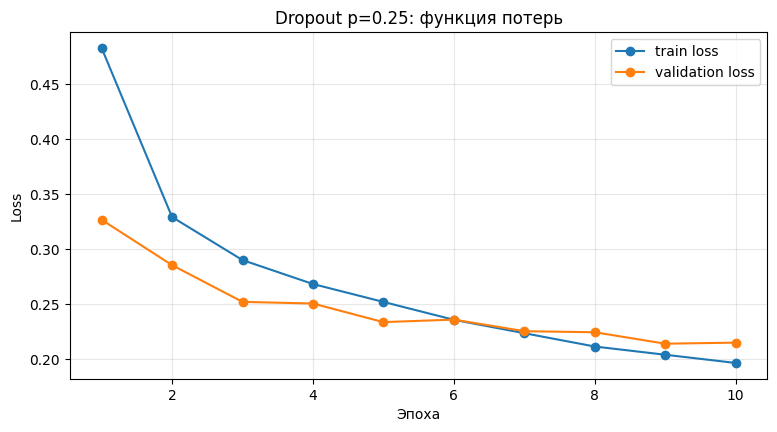

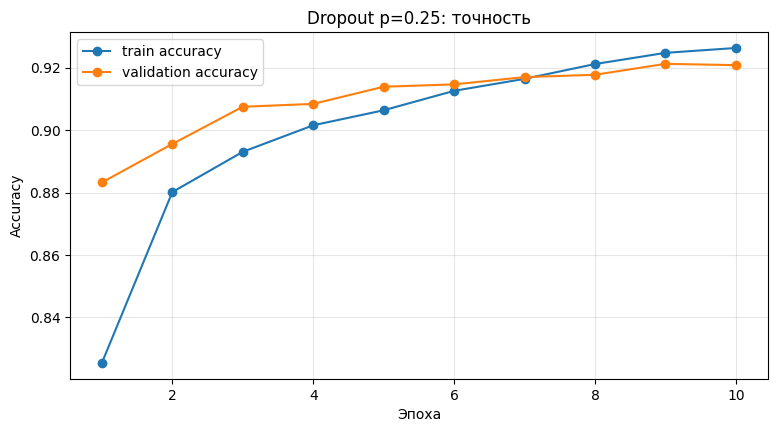

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (3 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Эксперимент: Dropout2d p=0.25
Обучаемых параметров: 421,834
{'best_loss_epoch': 10, 'best_val_loss': 0.217984452843666, 'best_val_accuracy': 0.921833336353302}


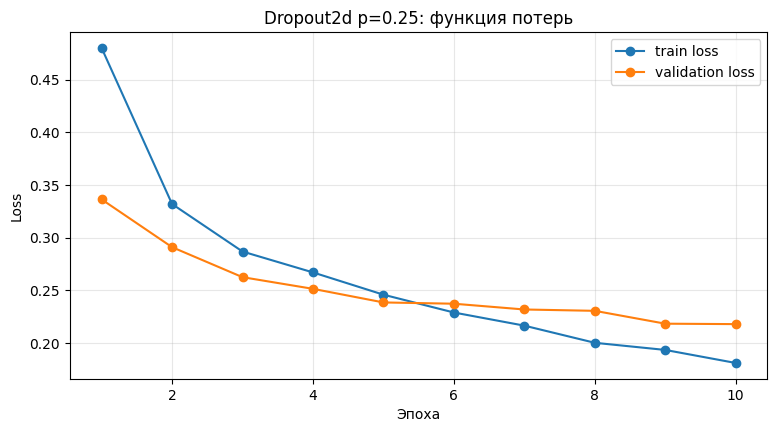

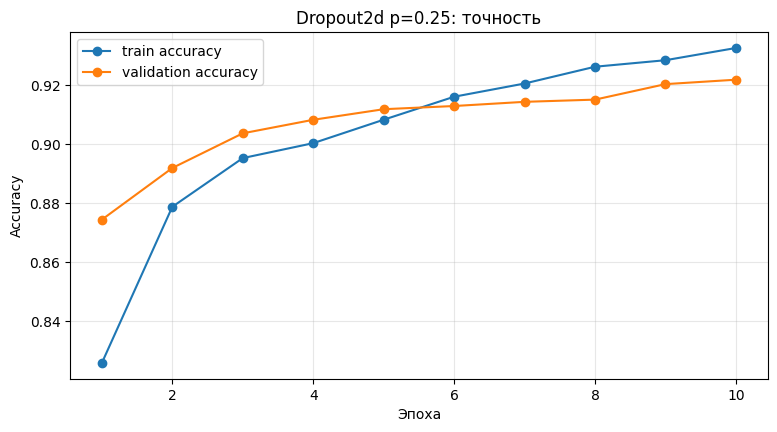

In [16]:
# Ваше задание: запустите эти варианты, чтобы сравнить обычный Dropout и Dropout2d при одинаковом p.
dropout_model, dropout_history = fit_cnn_variant(
    "Dropout p=0.25", dropout_type="dropout", dropout_p=0.25, experiments=experiments
)
plot_history(dropout_history, "Dropout p=0.25")

dropout2d_model, dropout2d_history = fit_cnn_variant(
    "Dropout2d p=0.25",
    dropout_type="dropout2d",
    dropout_p=0.25,
    experiments=experiments,
)
plot_history(dropout2d_history, "Dropout2d p=0.25")

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (3 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Эксперимент: С BatchNorm
Обучаемых параметров: 421,834
{'best_loss_epoch': 5, 'best_val_loss': 0.225412368774414, 'best_val_accuracy': 0.9194166660308838}


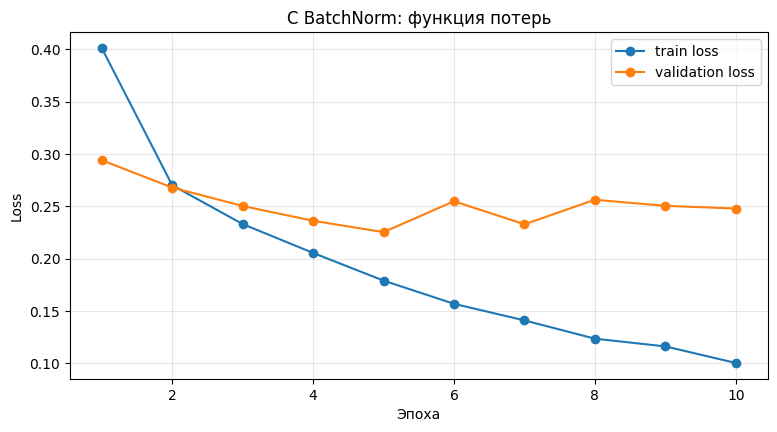

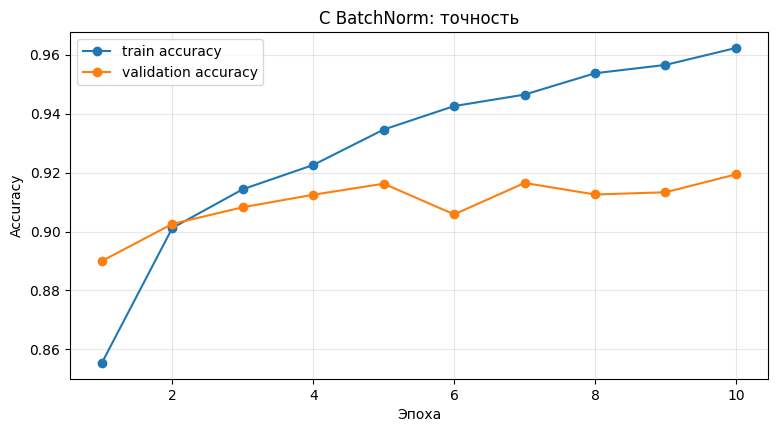

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (3 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Эксперимент: С BatchNorm и Dropout2d
Обучаемых параметров: 421,834
{'best_loss_epoch': 10, 'best_val_loss': 0.2208084762096405, 'best_val_accuracy': 0.9203333258628844}


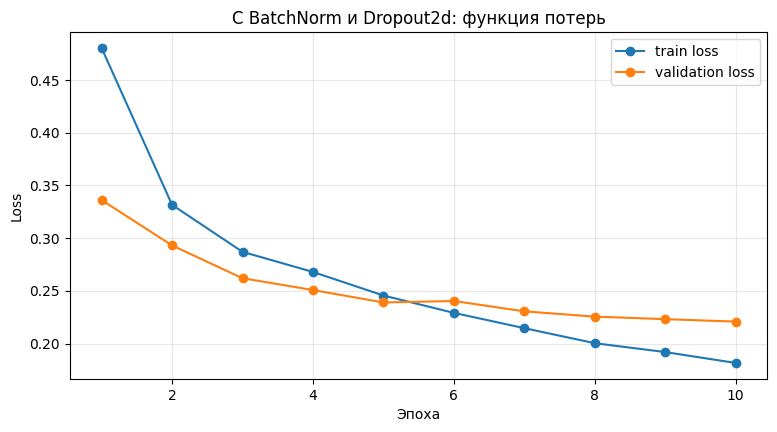

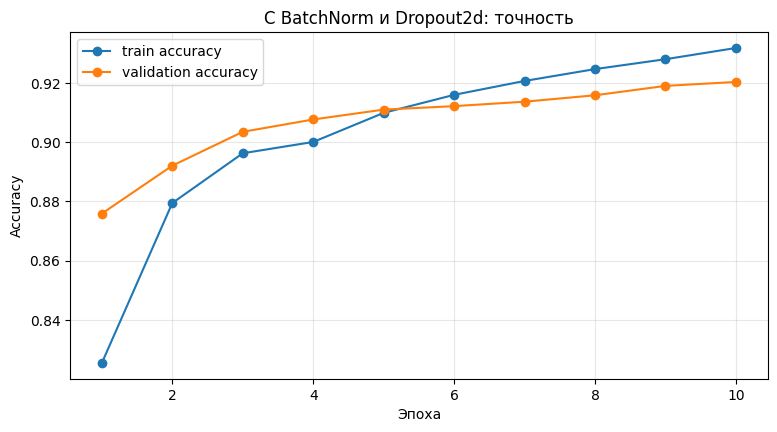

In [19]:
# Ваше задание: запустите вариант с BatchNorm, оставив остальные параметры базовой CNN неизменными.
batch_norm_model, batch_norm_history = fit_cnn_variant(
    "С BatchNorm", use_batch_norm=True, experiments=experiments
)
plot_history(batch_norm_history, "С BatchNorm")

dropout2d_batch_norm_model, dropout2d_batch_norm_history = fit_cnn_variant(
    "С BatchNorm и Dropout2d",
    use_batch_norm=True,
    dropout_type="dropout2d",
    dropout_p=0.25,
    experiments=experiments,
)
plot_history(dropout2d_batch_norm_history, "С BatchNorm и Dropout2d")

In [20]:
# Примеры конфигураций для отдельных запусков; выполняйте их по одной и сравнивайте с baseline.
larger_kernel = fit_cnn_variant("Ядро 5x5", kernel_size=5, experiments=experiments)
larger_stride = fit_cnn_variant("Stride 2", stride=2, experiments=experiments)
fewer_channels = fit_cnn_variant(
    "Каналы 16-32", channels=(16, 32), experiments=experiments
)
more_channels = fit_cnn_variant(
    "Каналы 64-128", channels=(64, 128), experiments=experiments
)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (42 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Эксперимент: Каналы 64-128
Обучаемых параметров: 879,114
{'best_loss_epoch': 7, 'best_val_loss': 0.2258508950471878, 'best_val_accuracy': 0.9241666793823242}


In [21]:
# experiments.insert(
#     0,
#     {
#         "Эксперимент": "Baseline CNN",
#         "Параметры": count_parameters(baseline_model),
#         **summarize_history(baseline_history),
#     },
# )

experiment_table = pd.DataFrame(experiments)
experiment_table

,Эксперимент,Параметры,best_loss_epoch,best_val_loss,best_val_accuracy
0,Baseline,421834,7,0.225345,0.920583
1,Dropout p=0.25,421834,9,0.214301,0.921250
2,Dropout2d p=0.25,421834,10,0.217984,0.921833
3,С BatchNorm,421834,5,0.225412,0.919417
4,С BatchNorm и Dropout2d,421834,10,0.220808,0.920333
5,Ядро 5x5,455114,7,0.218934,0.923333
6,Stride 2,53194,7,0.284464,0.898500
7,Каналы 16-32,207018,8,0.238236,0.919250
8,Каналы 64-128,879114,7,0.225851,0.924167


In [22]:
# Получаем предсказанные классы и истинные метки для всей тестовой выборки.
@torch.inference_mode()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Возвращает истинные метки, предсказания и вероятности классов."""
    model.eval()

    all_targets: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for features, labels in loader:
        # Переносим признаки на то же устройство, где расположена модель.
        features = features.to(target_device)

        # Модель возвращает логиты; Softmax преобразует их в вероятности для анализа.
        logits = model(features)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_targets.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


Подробный отчёт:
              precision    recall  f1-score   support

 T-shirt/top     0.8386    0.8940    0.8654      1000
     Trouser     0.9929    0.9810    0.9869      1000
    Pullover     0.8451    0.9000    0.8717      1000
       Dress     0.9008    0.9350    0.9176      1000
        Coat     0.8601    0.8850    0.8724      1000
      Sandal     0.9938    0.9620    0.9776      1000
       Shirt     0.8248    0.6730    0.7412      1000
     Sneaker     0.9551    0.9580    0.9566      1000
         Bag     0.9860    0.9850    0.9855      1000
  Ankle boot     0.9455    0.9720    0.9586      1000

    accuracy                         0.9145     10000
   macro avg     0.9143    0.9145    0.9133     10000
weighted avg     0.9143    0.9145    0.9133     10000



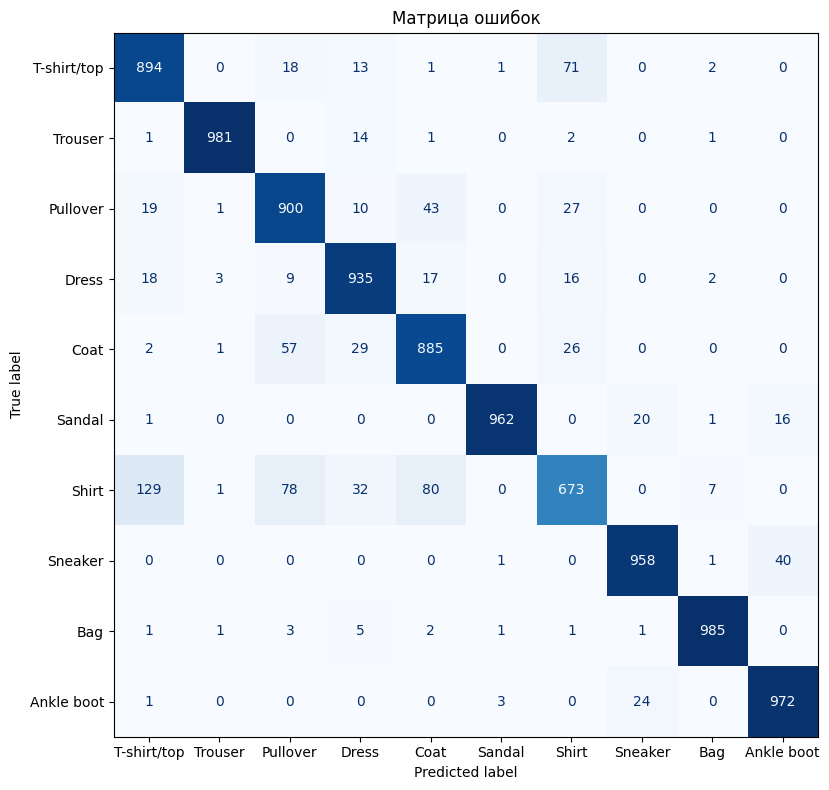

In [24]:
# Выполняем итоговую оценку выбранной модели на test.
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_true, y_pred, y_probabilities = collect_predictions(
    dropout2d_batch_norm_model, test_loader, device
)

print("\nПодробный отчёт:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

# Количество объектов всех классов одинаково.
confusion = confusion_matrix(y_true, y_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(8.5, 8))
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
)
confusion_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матрица ошибок")
plt.tight_layout()
plt.show()